<div dir="rtl" style="text-align:right">

# 🩻 Chest X-Ray — تصنيف ثلاثي (Normal / Bacterial / Viral) — النسخة v4 المضبوطة
### ما الذي تغيّر عن النسخة السابقة؟

| المشكلة في النسخة السابقة | الإصلاح هنا |
|---|---|
| دقة CV ≈ 79% لكن Test = 45% (إجابة شبه ثابتة "Bacterial") | **فحص إعادة التحميل**: بعد كل Fold نُحمّل الـ checkpoint ونتأكد أنه يعطي نفس دقة التحقق، فيُكشف أي خلل تلقائياً |
| تقييم "Ultimate" على Fold واحد فقط مع معايرة من نموذج آخر | تدريب الـ 5 Folds كاملة بنفس الإعدادات ثم Ensemble |
| Focal + أوزان فئات + Label Smoothing + MixUp/CutMix معاً (تنظيم مفرط) | CE + Label Smoothing خفيف + أوزان فئات مخففة (جذر) + MixUp أقل |
| دقة 224 فقط | دقة أعلى (288) مناسبة لتفاصيل الرئة |
| OneCycle من أول خطوة | تجميد الجسم حلقة واحدة (Head warm-up) ثم Warm-up + Cosine، واستثناء bias/Norm من weight decay |
| الاختيار بـ AUC (لا يعكس الدقة) | الاختيار بـ Macro-F1 |
| تطابق شبه مكرر بين مرضى مختلفين غير مكتشف | تجميع الصور المتشابهة جداً (dHash) مع معرّف المريض قبل التقسيم |
| لا ضبط لانحياز الفئات | **Logit bias** يُضبط على OOF فقط (بلا أي لمس للـ Test) |

> ⚠️ **عن هدف "دقة 100%":** لا يوجد ضبط مشروع يضمن ذلك. مفصل Viral/Bacterial في أشعة الصدر صعب حتى على أخصائيي الأشعة، وأي نتيجة 100% على Test تعني غالباً تسرّباً (نفس المريض في التدريب والاختبار) أو ضبطاً على Test. هذه النسخة تهدف لأعلى دقة **صادقة** قابلة للتعميم، والتقييم النهائي يُجرى مرة واحدة على Test معزول.

> للاستخدام التعليمي والبحثي فقط، وليس للتشخيص الطبي.

</div>

<div dir="rtl" style="text-align:right">

## 1️⃣ الإعداد

</div>

In [1]:
import sys, subprocess
def _pip(*p): subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *p])
for mod, pkg in [("timm", "timm>=0.9"), ("torchxrayvision", "torchxrayvision"),
                 ("kagglehub", "kagglehub"), ("cv2", "opencv-python-headless")]:
    try: __import__(mod)
    except ImportError: _pip(pkg)

import os, re, json, time, copy, random, hashlib, warnings, itertools
from dataclasses import dataclass, asdict
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
from tqdm.auto import tqdm
from IPython.display import display

import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim.swa_utils import AveragedModel, get_ema_multi_avg_fn
import torchvision.transforms.v2 as T
import torchvision.transforms.v2.functional as TF
import timm

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix, classification_report)
from sklearn.preprocessing import label_binarize
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"torch {torch.__version__} | timm {timm.__version__} | device: {device}")

torch 2.14.1+cu130 | timm 1.0.31 | device: cuda


<div dir="rtl" style="text-align:right">

## 2️⃣ التكوين
- `run_folds`: ضعه `1` لتجربة سريعة، و`5` للتدريب الكامل (Ensemble).
- إن كان الـ GPU ضعيفاً: `img_size=224`, `cache_size=256`, `batch_size=32`.

</div>

In [2]:
@dataclass
class CFG:
    backbone: str = "efficientnetv2_s"   # efficientnetv2_s | convnext_tiny | densenet121 | xrv_densenet121
    img_size: int = 288
    cache_size: int = 320
    batch_size: int = 32
    epochs: int = 18
    freeze_epochs: int = 1               # تدريب الرأس فقط في أول حلقة
    warmup_frac: float = 0.1
    lr_backbone: float = 2e-4
    lr_head: float = 1e-3
    weight_decay: float = 0.05
    dropout: float = 0.3
    label_smoothing: float = 0.1
    class_weight_power: float = 0.5      # 0 = بلا أوزان، 1 = موازنة كاملة
    mix_prob: float = 0.2
    mixup_alpha: float = 0.2
    cutmix_alpha: float = 1.0
    ema_decay: float = 0.995
    monitor: str = "f1_macro"            # f1_macro | bal_acc | acc | auc
    patience: int = 6
    n_folds: int = 5
    run_folds: int = 5                   # 1 = تجربة سريعة
    test_folds: int = 6
    use_clahe: bool = True
    num_workers: int = 2                 # على Windows استخدم 0
    use_amp: bool = True
    seed: int = 42
    out_dir: str = "outputs_v4"

cfg = CFG()
cfg.use_amp = cfg.use_amp and device.type == "cuda"
Path(cfg.out_dir).mkdir(parents=True, exist_ok=True)

def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.benchmark = True
seed_everything(cfg.seed)
print(asdict(cfg))

{'backbone': 'efficientnetv2_s', 'img_size': 288, 'cache_size': 320, 'batch_size': 32, 'epochs': 18, 'freeze_epochs': 1, 'warmup_frac': 0.1, 'lr_backbone': 0.0002, 'lr_head': 0.001, 'weight_decay': 0.05, 'dropout': 0.3, 'label_smoothing': 0.1, 'class_weight_power': 0.5, 'mix_prob': 0.2, 'mixup_alpha': 0.2, 'cutmix_alpha': 1.0, 'ema_decay': 0.995, 'monitor': 'f1_macro', 'patience': 6, 'n_folds': 5, 'run_folds': 5, 'test_folds': 6, 'use_clahe': True, 'num_workers': 2, 'use_amp': True, 'seed': 42, 'out_dir': 'outputs_v4'}


<div dir="rtl" style="text-align:right">

## 3️⃣ البيانات
تُحمَّل من Kaggle (`chest-xray-pneumonia`). المجلد الأصلي ثنائي (Normal/Pneumonia)، لكن أسماء ملفات الالتهاب تحتوي `bacteria` أو `virus`، فنستخرج منها الفئة الثلاثية.
لتجاوز التحميل: عيّن `DATA_DIR` يدوياً.

</div>

In [3]:
import kagglehub
DATA_DIR = None
KAGGLE_DATASET = "paultimothymooney/chest-xray-pneumonia"
if DATA_DIR is None:
    DATA_DIR = kagglehub.dataset_download(KAGGLE_DATASET)
DATA_DIR = Path(DATA_DIR)

def find_root(path):
    path = Path(path)
    if (path / "train").exists(): return path
    for p in path.rglob("train"):
        if p.is_dir() and (p.parent / "test").exists(): return p.parent
    return path
ROOT = find_root(DATA_DIR)

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
def label_of(path):
    n = path.name.lower()
    if "bacteria" in n: return "BACTERIAL_PNEUMONIA"
    if "virus" in n:    return "VIRAL_PNEUMONIA"
    if "normal" in str(path.relative_to(ROOT)).lower(): return "NORMAL"
    return None

rows = []
for split in ["train", "val", "test"]:
    d = ROOT / split
    if not d.exists(): continue
    for p in d.rglob("*"):
        if p.is_file() and p.suffix.lower() in IMG_EXT:
            lab = label_of(p)
            if lab: rows.append({"path": str(p), "label": lab, "orig_split": split})
df = pd.DataFrame(rows)
assert len(df), "لم يتم العثور على صور"
print(df.groupby(["orig_split", "label"]).size())

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
orig_split  label              
test        BACTERIAL_PNEUMONIA     242
            NORMAL                  234
            VIRAL_PNEUMONIA         148
train       BACTERIAL_PNEUMONIA    2530
            NORMAL                 1341
            VIRAL_PNEUMONIA        1345
val         BACTERIAL_PNEUMONIA       8
            NORMAL                    8
dtype: int64


<div dir="rtl" style="text-align:right">

## 4️⃣ تدقيق البيانات + منع التسرب
1. حذف التكرارات الحرفية (MD5).
2. معرّف المريض من اسم الملف.
3. **دمج الصور المتشابهة جداً** (dHash 16×16) في نفس المجموعة، حتى لا تتوزع نسخ شبه متطابقة بين التدريب والاختبار.
4. عزل Test نهائي على مستوى المجموعة ثم K-Fold على الباقي.

</div>

In [4]:
def md5_file(p):
    with open(p, "rb") as f: return hashlib.md5(f.read()).hexdigest()

def patient_id(path):
    name = Path(path).stem
    m = re.search(r"(person\d+)", name, re.I) or re.search(r"(IM-\d+)", name, re.I)
    return m.group(1) if m else name

all_df = df.copy()
with ThreadPoolExecutor(8) as ex:
    all_df["hash"] = list(tqdm(ex.map(md5_file, all_df.path), total=len(all_df), desc="hashing"))
n0 = len(all_df)
all_df = all_df.drop_duplicates("hash").reset_index(drop=True)
print(f"Images: {n0} -> {len(all_df)} (removed {n0-len(all_df)} exact duplicates)")

classes = sorted(all_df.label.unique())
class_to_idx = {c: i for i, c in enumerate(classes)}
NUM_CLASSES = len(classes)
assert NUM_CLASSES == 3, f"المطلوب 3 فئات لكن وُجد {classes}"
all_df["y"] = all_df.label.map(class_to_idx)
all_df["group"] = all_df.path.map(patient_id)
print("Classes:", class_to_idx, "| groups before near-dup merge:", all_df.group.nunique())

hashing:   0%|          | 0/5856 [00:00<?, ?it/s]

Images: 5856 -> 5824 (removed 32 exact duplicates)
Classes: {'BACTERIAL_PNEUMONIA': 0, 'NORMAL': 1, 'VIRAL_PNEUMONIA': 2} | groups before near-dup merge: 2790


<div dir="rtl" style="text-align:right">

## 5️⃣ التحميل المسبق في الذاكرة (CLAHE) + دمج المتشابهات

</div>

In [5]:
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
def load_gray(path, size=cfg.cache_size, use_clahe=cfg.use_clahe):
    img = np.array(Image.open(path).convert("L"))
    img = cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)
    return clahe.apply(img) if use_clahe else img

with ThreadPoolExecutor(8) as ex:
    arrs = list(tqdm(ex.map(load_gray, all_df.path), total=len(all_df), desc="caching"))
CACHE = dict(zip(all_df.path, arrs))
print(f"Cached {len(CACHE)} images | ~{sum(a.nbytes for a in arrs)/1e6:.0f} MB")

# ---- near-duplicate grouping (dHash 16x16 = 256 bit) ----
def dhash(a, n=16):
    s = cv2.resize(a, (n + 1, n), interpolation=cv2.INTER_AREA).astype(np.int16)
    return (s[:, 1:] > s[:, :-1]).flatten().astype(np.float32)
H = np.stack([dhash(a) for a in arrs])                  # (N, 256)
parent = list(range(len(H)))
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]; i = parent[i]
    return i
def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb: parent[rb] = ra

NEAR_DUP_MAX_HAMMING = 10                                # ~4% من البتات
Hn = 1.0 - H
for s in range(0, len(H), 512):
    ham = H.shape[1] - (H[s:s+512] @ H.T + Hn[s:s+512] @ Hn.T)
    ii, jj = np.where(ham <= NEAR_DUP_MAX_HAMMING)
    for i, j in zip(ii + s, jj):
        if i < j: union(int(i), int(j))

# ادمج مع معرّف المريض: كل صور المكوّن المتصل تأخذ نفس المجموعة
comp = np.array([find(i) for i in range(len(H))])
g_parent = {}
def gfind(x):
    while g_parent.setdefault(x, x) != x:
        g_parent[x] = g_parent[g_parent[x]]; x = g_parent[x]
    return x
for pid, c in zip(all_df.group, comp):
    ra, rb = gfind(("p", pid)), gfind(("c", int(c)))
    if ra != rb: g_parent[rb] = ra
all_df["group"] = [str(gfind(("p", pid))) for pid in all_df.group]
sizes = all_df.group.value_counts()
print(f"groups after near-dup merge: {all_df.group.nunique()} | largest group: {sizes.iloc[0]} images")
if sizes.iloc[0] > 60:
    print("⚠️ مجموعة كبيرة جداً؛ قلّل NEAR_DUP_MAX_HAMMING إلى 6 وأعد التشغيل.")
display(all_df.groupby("label").size().rename("images").to_frame())

caching:   0%|          | 0/5824 [00:00<?, ?it/s]

Cached 5824 images | ~596 MB
groups after near-dup merge: 2790 | largest group: 31 images


,images
label,
BACTERIAL_PNEUMONIA,2760
NORMAL,1579
VIRAL_PNEUMONIA,1485


Dev: 4890 | Test (held-out): 934 | folds: 5


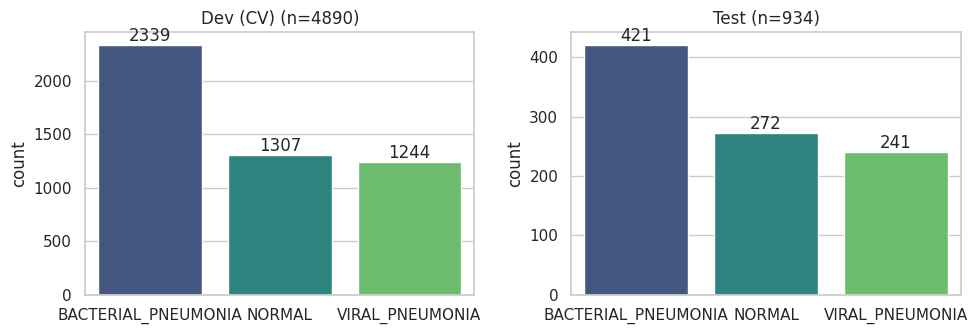

In [6]:
sgkf_test = StratifiedGroupKFold(n_splits=cfg.test_folds, shuffle=True, random_state=cfg.seed)
dev_idx, test_idx = next(sgkf_test.split(all_df, all_df.y, all_df.group))
dev_df  = all_df.iloc[dev_idx].reset_index(drop=True)
test_df = all_df.iloc[test_idx].reset_index(drop=True)
assert set(dev_df.group).isdisjoint(set(test_df.group))

sgkf = StratifiedGroupKFold(n_splits=cfg.n_folds, shuffle=True, random_state=cfg.seed)
folds = list(sgkf.split(dev_df, dev_df.y, dev_df.group))
for a, b in folds:
    assert set(dev_df.group.iloc[a]).isdisjoint(set(dev_df.group.iloc[b]))
print(f"Dev: {len(dev_df)} | Test (held-out): {len(test_df)} | folds: {cfg.n_folds}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for a, (n, d) in zip(ax, [("Dev (CV)", dev_df), ("Test", test_df)]):
    sns.countplot(data=d, x="label", order=classes, ax=a, palette="viridis"); a.set_title(f"{n} (n={len(d)})")
    a.set_xlabel("")
    for c in a.containers: a.bar_label(c)
plt.tight_layout(); plt.show()

<div dir="rtl" style="text-align:right">

## 6️⃣ Augmentation
تحويلات طبية معقولة (بلا قلب أفقي لأن القلب في جهة محددة).

</div>

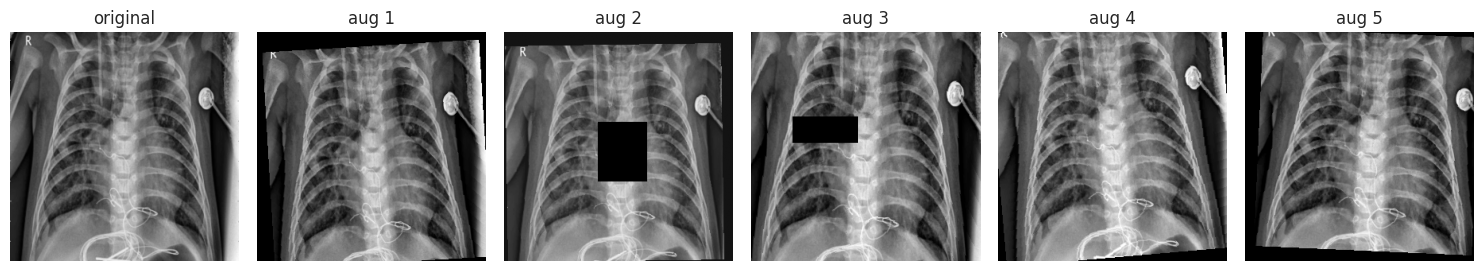

In [7]:
train_tfm = T.Compose([
    T.RandomResizedCrop(cfg.img_size, scale=(0.8, 1.0), ratio=(0.92, 1.08), antialias=True),
    T.RandomAffine(degrees=7, translate=(0.04, 0.04), scale=(0.93, 1.07)),
    T.ColorJitter(brightness=0.2, contrast=0.2),
    T.RandomApply([T.GaussianBlur(3, sigma=(0.1, 0.8))], p=0.1),
    T.ToDtype(torch.float32, scale=True),
    T.RandomErasing(p=0.15, scale=(0.02, 0.06), value=0),
])
eval_tfm = T.Compose([T.Resize((cfg.img_size, cfg.img_size), antialias=True),
                      T.ToDtype(torch.float32, scale=True)])

class XrayDS(Dataset):
    def __init__(self, df, tfm):
        self.paths, self.y, self.tfm = df.path.tolist(), df.y.tolist(), tfm
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        x = torch.from_numpy(CACHE[self.paths[i]]).unsqueeze(0)
        return self.tfm(x), self.y[i]

def make_loader(df, tfm, shuffle, bs=None):
    return DataLoader(XrayDS(df, tfm), batch_size=bs or cfg.batch_size, shuffle=shuffle,
                      drop_last=shuffle, num_workers=cfg.num_workers,
                      pin_memory=device.type == "cuda", persistent_workers=cfg.num_workers > 0)

r = dev_df.iloc[0]
fig, ax = plt.subplots(1, 6, figsize=(15, 2.8))
ax[0].imshow(eval_tfm(torch.from_numpy(CACHE[r.path]).unsqueeze(0))[0], cmap="gray"); ax[0].set_title("original")
for i in range(1, 6):
    ax[i].imshow(XrayDS(dev_df.iloc[[0]], train_tfm)[0][0][0], cmap="gray"); ax[i].set_title(f"aug {i}")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

<div dir="rtl" style="text-align:right">

## 7️⃣ النموذج، الخسارة، MixUp/CutMix

</div>

In [8]:
TIMM_NAMES = {"densenet121": "densenet121.ra_in1k",
              "convnext_tiny": "convnext_tiny.fb_in22k_ft_in1k",
              "efficientnetv2_s": "tf_efficientnetv2_s.in21k_ft_in1k"}
TIMM_KW = {"densenet121": {}, "convnext_tiny": {"drop_path_rate": 0.1}, "efficientnetv2_s": {"drop_path_rate": 0.1}}

class XrayNet(nn.Module):
    def __init__(self, backbone, num_classes, dropout=0.3, pretrained=True):
        super().__init__()
        self.backbone_name = backbone
        if backbone == "xrv_densenet121":
            import torchxrayvision as xrv
            base = xrv.models.DenseNet(weights="densenet121-res224-all" if pretrained else None)
            self.body, feat_dim, self.kind = base.features, 1024, "xrv"
        else:
            self.body = timm.create_model(TIMM_NAMES[backbone], pretrained=pretrained, num_classes=0, **TIMM_KW[backbone])
            feat_dim, self.kind = self.body.num_features, "timm"
            dc = timm.data.resolve_data_config({}, model=self.body)
            self.register_buffer("mean", torch.tensor(dc["mean"]).view(1, 3, 1, 1))
            self.register_buffer("std", torch.tensor(dc["std"]).view(1, 3, 1, 1))
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(feat_dim, num_classes))

    def forward(self, x):                      # x: (B,1,H,W) in [0,1]
        if self.kind == "xrv":
            f = F.relu(self.body(x * 2048.0 - 1024.0))
            f = F.adaptive_avg_pool2d(f, 1).flatten(1)
        else:
            f = self.body((x.expand(-1, 3, -1, -1) - self.mean) / self.std)
        return self.head(f)

def gradcam_layer(m):
    return {"xrv_densenet121": lambda: m.body.denseblock4,
            "densenet121": lambda: m.body.features.denseblock4,
            "convnext_tiny": lambda: m.body.stages[-1],
            "efficientnetv2_s": lambda: m.body.blocks[-1]}[m.backbone_name]()

def build_loss(cfg, y_train):
    cw = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=y_train) ** cfg.class_weight_power
    w = torch.tensor(cw / cw.mean(), dtype=torch.float32, device=device)
    return nn.CrossEntropyLoss(weight=w, label_smoothing=cfg.label_smoothing)

def apply_mix(x, y, cfg):
    if cfg.mix_prob <= 0 or random.random() > cfg.mix_prob:
        return x, y, y, 1.0
    perm = torch.randperm(x.size(0), device=x.device)
    if random.random() < 0.5:                                   # MixUp
        lam = float(np.random.beta(cfg.mixup_alpha, cfg.mixup_alpha))
        x = lam * x + (1 - lam) * x[perm]
    else:                                                       # CutMix
        lam = float(np.random.beta(cfg.cutmix_alpha, cfg.cutmix_alpha))
        H_, W_ = x.shape[-2:]
        r = np.sqrt(1 - lam); h, w = int(H_ * r), int(W_ * r)
        cy, cx = np.random.randint(H_), np.random.randint(W_)
        y1, y2 = np.clip(cy - h // 2, 0, H_), np.clip(cy + h // 2, 0, H_)
        x1, x2 = np.clip(cx - w // 2, 0, W_), np.clip(cx + w // 2, 0, W_)
        x = x.clone(); x[:, :, y1:y2, x1:x2] = x[perm][:, :, y1:y2, x1:x2]
        lam = 1 - (y2 - y1) * (x2 - x1) / (H_ * W_)
    return x, y, y[perm], lam

m_ = XrayNet(cfg.backbone, NUM_CLASSES, pretrained=True)
print(cfg.backbone, f"-> {sum(p.numel() for p in m_.parameters())/1e6:.1f}M params"); del m_

model.safetensors: reconstructing file:   0%|          |  0.00B / 86.5MB            

model.safetensors: downloading bytes:           |  0.00B            

efficientnetv2_s -> 20.2M params


<div dir="rtl" style="text-align:right">

## 8️⃣ دالة التدريب `run_fold`
Head warm-up (جسم مجمّد) ← فك التجميد • AdamW بمعدلين تعلم وبلا weight decay على bias/Norm • Warm-up + Cosine • AMP • Gradient Clipping • EMA • Early Stopping على `monitor`.

</div>

In [9]:
def softmax_np(z, T=1.0):
    z = z / T; z = z - z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)

def compute_metrics(y, probs):
    pred = probs.argmax(1)
    out = {"acc": accuracy_score(y, pred), "bal_acc": balanced_accuracy_score(y, pred),
           "f1_macro": f1_score(y, pred, average="macro")}
    try: out["auc"] = roc_auc_score(y, probs, multi_class="ovr", average="macro")
    except ValueError: out["auc"] = float("nan")
    return out

def tta_forward(model, x):
    zoom = TF.center_crop(F.interpolate(x, scale_factor=1.1, mode="bilinear", align_corners=False), list(x.shape[-2:]))
    views = [x, zoom, TF.rotate(x, 5), TF.rotate(x, -5)]
    return torch.stack([model(v).float() for v in views]).mean(0)

@torch.no_grad()
def predict_logits(model, loader, tta=False):
    model.eval(); outs, ys = [], []
    for x, y in loader:
        x = x.to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, enabled=cfg.use_amp):
            lg = tta_forward(model, x) if tta else model(x).float()
        outs.append(lg.float().cpu()); ys.append(y)
    return torch.cat(outs).numpy(), torch.cat(ys).numpy()

def make_param_groups(model, cfg):
    groups = []
    for part, lr in [(model.body, cfg.lr_backbone), (model.head, cfg.lr_head)]:
        dec, nodec = [], []
        for n, p in part.named_parameters():
            (nodec if p.ndim <= 1 else dec).append(p)
        groups += [{"params": dec, "lr": lr, "weight_decay": cfg.weight_decay},
                   {"params": nodec, "lr": lr, "weight_decay": 0.0}]
    return groups

def set_body_trainable(model, flag):
    for p in model.body.parameters(): p.requires_grad = flag

def run_fold(cfg, tr_df, va_df, tag="fold", verbose=True):
    seed_everything(cfg.seed)
    tr_loader, va_loader = make_loader(tr_df, train_tfm, True), make_loader(va_df, eval_tfm, False)
    model = XrayNet(cfg.backbone, NUM_CLASSES, cfg.dropout).to(device)
    ema = AveragedModel(model, multi_avg_fn=get_ema_multi_avg_fn(cfg.ema_decay), use_buffers=True)
    crit = build_loss(cfg, tr_df.y.values)
    opt = torch.optim.AdamW(make_param_groups(model, cfg))
    total = cfg.epochs * len(tr_loader); warm = max(1, int(cfg.warmup_frac * total))
    lam_fn = lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + np.cos(np.pi * (s - warm) / max(1, total - warm)))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda=lam_fn)
    scaler = torch.amp.GradScaler("cuda", enabled=cfg.use_amp)

    best, best_state, best_logits, best_m, wait, hist = -1e9, None, None, None, 0, []
    for ep in range(1, cfg.epochs + 1):
        frozen = ep <= cfg.freeze_epochs
        set_body_trainable(model, not frozen)
        model.train()
        if frozen: model.body.eval()
        run, n, t0 = 0.0, 0, time.time()
        for x, y in tr_loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            x, ya, yb, lam = apply_mix(x, y, cfg)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, enabled=cfg.use_amp):
                out = model(x)
                loss = lam * crit(out.float(), ya) + (1 - lam) * crit(out.float(), yb)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step(); ema.update_parameters(model)
            run += loss.item() * len(y); n += len(y)

        lg, yv = predict_logits(ema, va_loader)
        m = compute_metrics(yv, softmax_np(lg))
        m["val_nll"] = float(F.cross_entropy(torch.tensor(lg), torch.tensor(yv)))
        hist.append({"epoch": ep, "train_loss": run / n, **m})
        score = m[cfg.monitor]
        if ep > cfg.freeze_epochs and score > best:
            best, wait, best_m, best_logits = score, 0, m, lg
            best_state = {k: v.detach().cpu().clone() for k, v in ema.module.state_dict().items()}
        elif ep > cfg.freeze_epochs:
            wait += 1
        if verbose:
            print(f"[{tag}] ep {ep:02d}{' (head only)' if frozen else ''} | loss {run/n:.4f} | val_nll {m['val_nll']:.4f} | "
                  f"acc {m['acc']:.4f} | F1 {m['f1_macro']:.4f} | AUC {m['auc']:.4f} | {time.time()-t0:.0f}s{' *' if wait == 0 and not frozen else ''}")
        if wait >= cfg.patience:
            if verbose: print(f"[{tag}] early stop @ {ep}")
            break
    return {"state": best_state, "val_logits": best_logits, "best": best, "best_metrics": best_m, "hist": pd.DataFrame(hist)}

def load_model(path):
    ck = torch.load(path, map_location="cpu")
    m = XrayNet(ck["cfg"]["backbone"], NUM_CLASSES, ck["cfg"]["dropout"], pretrained=False)
    m.load_state_dict(ck["state"]); return m.to(device).eval()

<div dir="rtl" style="text-align:right">

## 9️⃣ (اختياري) مقارنة الـ Backbones على Fold واحد
فعّلها مرة واحدة ثم ضع الفائز في `cfg.backbone`.

</div>

In [10]:
RUN_MODEL_SELECTION = False
CANDIDATES = ["efficientnetv2_s", "convnext_tiny", "xrv_densenet121"]
if RUN_MODEL_SELECTION:
    rows = []
    for name in CANDIDATES:
        c = copy.deepcopy(cfg); c.backbone, c.epochs = name, 10
        tr_i, va_i = folds[0]
        res = run_fold(c, dev_df.iloc[tr_i], dev_df.iloc[va_i], tag=name, verbose=False)
        rows.append({"backbone": name, **{k: round(v, 4) for k, v in res["best_metrics"].items()}})
        print(rows[-1])
    sel = pd.DataFrame(rows).sort_values(cfg.monitor, ascending=False).reset_index(drop=True)
    display(sel); cfg.backbone = sel.loc[0, "backbone"]; print("Selected:", cfg.backbone)

<div dir="rtl" style="text-align:right">

## 🔟 التدريب بالـ Cross-Validation + فحص إعادة التحميل
بعد كل Fold: نحفظ الـ checkpoint، نعيد تحميله، ونتحقق أن دقته على التحقق تطابق ما سُجّل أثناء التدريب. إن لم تتطابق يتوقف التنفيذ، وهذا هو الفحص الذي يكشف أي خلل في الحفظ/التحميل قبل أن يصل إلى Test.

</div>

In [11]:
oof, oof_tta = np.zeros((len(dev_df), NUM_CLASSES), np.float32), np.zeros((len(dev_df), NUM_CLASSES), np.float32)
done = np.zeros(len(dev_df), bool)
fold_results, ckpt_paths = [], []

for k, (tr_i, va_i) in enumerate(folds[:cfg.run_folds]):
    print(f"\n=== Fold {k+1}/{cfg.run_folds} | train {len(tr_i)} | val {len(va_i)} ===")
    res = run_fold(cfg, dev_df.iloc[tr_i], dev_df.iloc[va_i], tag=f"fold{k+1}")
    p = Path(cfg.out_dir) / f"{cfg.backbone}_fold{k+1}.pt"
    torch.save({"state": res["state"], "classes": classes, "cfg": asdict(cfg)}, p)

    # ---- sanity: reload from disk and re-score the validation fold ----
    va_loader = make_loader(dev_df.iloc[va_i], eval_tfm, False, bs=64)
    mdl = load_model(p)
    lg_plain, yv = predict_logits(mdl, va_loader, tta=False)
    lg_tta, _ = predict_logits(mdl, va_loader, tta=True)
    acc_re, acc_tr = accuracy_score(yv, lg_plain.argmax(1)), res["best_metrics"]["acc"]
    print(f"[fold{k+1}] reload acc {acc_re:.4f} vs training acc {acc_tr:.4f} | TTA acc {accuracy_score(yv, lg_tta.argmax(1)):.4f}")
    if abs(acc_re - acc_tr) > 0.01:
        raise RuntimeError("النموذج المُعاد تحميله لا يطابق نموذج التدريب: راجع الحفظ/التحميل قبل المتابعة.")
    oof[va_i], oof_tta[va_i], done[va_i] = lg_plain, lg_tta, True
    fold_results.append(res); ckpt_paths.append(p)
    del mdl; torch.cuda.empty_cache()

cv_table = pd.DataFrame([{"fold": i + 1, **r["best_metrics"]} for i, r in enumerate(fold_results)])
display(cv_table.round(4))
print("Mean ± std:\n", cv_table.drop(columns="fold").agg(["mean", "std"]).round(4))


=== Fold 1/5 | train 3873 | val 1017 ===
[fold1] ep 01 (head only) | loss 1.0456 | val_nll 1.0400 | acc 0.5811 | F1 0.4483 | AUC 0.7244 | 33s
[fold1] ep 02 | loss 0.7729 | val_nll 0.8603 | acc 0.7139 | F1 0.6018 | AUC 0.8726 | 52s *
[fold1] ep 03 | loss 0.6676 | val_nll 0.5878 | acc 0.7994 | F1 0.7593 | AUC 0.9195 | 39s *
[fold1] ep 04 | loss 0.6174 | val_nll 0.4930 | acc 0.8132 | F1 0.7894 | AUC 0.9348 | 41s *
[fold1] ep 05 | loss 0.5609 | val_nll 0.4550 | acc 0.8220 | F1 0.8068 | AUC 0.9389 | 40s *
[fold1] ep 06 | loss 0.5163 | val_nll 0.4434 | acc 0.8269 | F1 0.8120 | AUC 0.9411 | 41s *
[fold1] ep 07 | loss 0.4797 | val_nll 0.4461 | acc 0.8319 | F1 0.8191 | AUC 0.9394 | 41s *
[fold1] ep 08 | loss 0.4616 | val_nll 0.4524 | acc 0.8358 | F1 0.8230 | AUC 0.9372 | 41s *
[fold1] ep 09 | loss 0.4395 | val_nll 0.4648 | acc 0.8309 | F1 0.8191 | AUC 0.9351 | 42s
[fold1] ep 10 | loss 0.4317 | val_nll 0.4777 | acc 0.8279 | F1 0.8164 | AUC 0.9340 | 41s
[fold1] ep 11 | loss 0.4171 | val_nll 0.49

,fold,acc,bal_acc,f1_macro,auc,val_nll
0,1,0.8358,0.8265,0.8230,0.9372,0.4524
1,2,0.8309,0.8306,0.8302,0.9158,0.5119
2,3,0.8106,0.8024,0.7990,0.9146,0.5481
3,4,0.8356,0.8242,0.8215,0.9293,0.4915
4,5,0.8126,0.8162,0.8076,0.9104,0.5583


Mean ± std:
          acc  bal_acc  f1_macro     auc  val_nll
mean  0.8251   0.8200    0.8163  0.9215   0.5124
std   0.0125   0.0111    0.0127  0.0113   0.0431


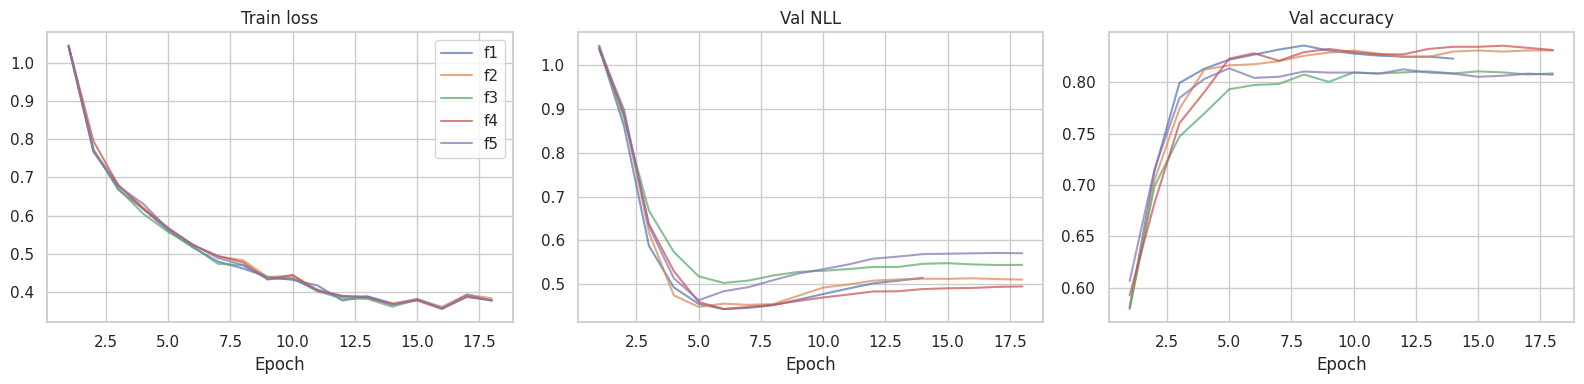

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for i, r in enumerate(fold_results):
    h = r["hist"]
    ax[0].plot(h.epoch, h.train_loss, alpha=.7, label=f"f{i+1}")
    ax[1].plot(h.epoch, h.val_nll, alpha=.7); ax[2].plot(h.epoch, h.acc, alpha=.7)
ax[0].set_title("Train loss"); ax[1].set_title("Val NLL"); ax[2].set_title("Val accuracy"); ax[0].legend()
for a in ax: a.set_xlabel("Epoch")
plt.tight_layout(); plt.savefig(Path(cfg.out_dir) / "cv_curves.png", dpi=150); plt.show()

<div dir="rtl" style="text-align:right">

## 1️⃣1️⃣ تحليل OOF: TTA، المعايرة، وانحياز الفئات
كل القرارات هنا (استخدام TTA، درجة الحرارة، الـ bias) تُحسب من تنبؤات **Out-of-Fold** فقط، فلا يلمس الـ Test أي قرار تصميمي.

</div>

In [13]:
y_dev = dev_df.y.values[done]
O, OT = oof[done], oof_tta[done]
m_plain, m_tta = compute_metrics(y_dev, softmax_np(O)), compute_metrics(y_dev, softmax_np(OT))
print("OOF plain:", {k: round(float(v), 4) for k, v in m_plain.items()})
print("OOF + TTA:", {k: round(float(v), 4) for k, v in m_tta.items()})
USE_TTA = m_tta["f1_macro"] >= m_plain["f1_macro"]
O_sel = OT if USE_TTA else O
print("USE_TTA =", USE_TTA)

def fit_temperature(logits, y):
    ts = np.linspace(0.3, 5.0, 236)
    nll = [F.cross_entropy(torch.tensor(logits / t), torch.tensor(y)).item() for t in ts]
    return float(ts[int(np.argmin(nll))])

def ece_score(probs, y, bins=15):
    conf, ok = probs.max(1), probs.argmax(1) == y
    edges, e = np.linspace(0, 1, bins + 1), 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        mk = (conf > lo) & (conf <= hi)
        if mk.any(): e += mk.mean() * abs(ok[mk].mean() - conf[mk].mean())
    return e

def fit_logit_bias(logits, y, grid=np.linspace(-1.0, 1.0, 21), min_gain=0.003):
    base = f1_score(y, logits.argmax(1), average="macro")
    best_f1, best_b = base, np.zeros(NUM_CLASSES)
    for combo in itertools.product(grid, repeat=NUM_CLASSES - 1):
        b = np.array([0.0, *combo])
        f = f1_score(y, (logits + b).argmax(1), average="macro")
        if f > best_f1 + 1e-9 or (abs(f - best_f1) < 1e-9 and np.abs(b).sum() < np.abs(best_b).sum()):
            best_f1, best_b = f, b
    return (best_b, best_f1) if best_f1 - base >= min_gain else (np.zeros(NUM_CLASSES), base)

LOGIT_BIAS, f1_b = fit_logit_bias(O_sel, y_dev)
T_OPT = fit_temperature(O_sel + LOGIT_BIAS, y_dev)
print(f"Logit bias = {np.round(LOGIT_BIAS, 2)} (OOF macro-F1 {f1_score(y_dev, O_sel.argmax(1), average='macro'):.4f} -> {f1_b:.4f})")
print(f"Temperature = {T_OPT:.3f} | ECE {ece_score(softmax_np(O_sel), y_dev):.4f} -> {ece_score(softmax_np(O_sel + LOGIT_BIAS, T_OPT), y_dev):.4f}")

OOF plain: {'acc': 0.8249, 'bal_acc': 0.8199, 'f1_macro': 0.8162, 'auc': 0.9211}
OOF + TTA: {'acc': 0.8215, 'bal_acc': 0.8241, 'f1_macro': 0.8212, 'auc': 0.9003}
USE_TTA = True
Logit bias = [0. 0. 0.] (OOF macro-F1 0.8212 -> 0.8212)
Temperature = 0.580 | ECE 0.1840 -> 0.1234


<div dir="rtl" style="text-align:right">

## 1️⃣2️⃣ التقييم النهائي على Test المعزول (يُشغَّل مرة واحدة)

</div>

In [14]:
ens_models = [load_model(p) for p in ckpt_paths]
test_loader = make_loader(test_df, eval_tfm, False, bs=64)

fold_logits = []
for m in ens_models:
    lg, y_test = predict_logits(m, test_loader, tta=USE_TTA); fold_logits.append(lg)
print("Single-model test acc:", np.round([accuracy_score(y_test, l.argmax(1)) for l in fold_logits], 4))

test_logits = np.mean(fold_logits, axis=0) + LOGIT_BIAS
test_probs = softmax_np(test_logits, T_OPT)

def bootstrap_ci(y, p, key, n=1000, seed=0):
    rng, vals = np.random.default_rng(seed), []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        v = compute_metrics(y[i], p[i])[key]
        if not np.isnan(v): vals.append(v)
    return np.percentile(vals, [2.5, 97.5])

metrics = compute_metrics(y_test, test_probs)
print("\n=== TEST (Ensemble) ===")
for k, v in metrics.items():
    lo, hi = bootstrap_ci(y_test, test_probs, k)
    print(f"{k:9s}: {v:.4f}   95% CI [{lo:.4f}, {hi:.4f}]")
print("\n" + classification_report(y_test, test_probs.argmax(1), target_names=classes, digits=4))
print("Test ECE:", round(ece_score(test_probs, y_test), 4))
print(f"OOF acc {m_tta['acc'] if USE_TTA else m_plain['acc']:.4f} vs Test acc {metrics['acc']:.4f}  (فجوة كبيرة = راجع التسرب/التوزيع)")

Single-model test acc: [0.8244 0.8201 0.8105 0.8019 0.8009]

=== TEST (Ensemble) ===
acc      : 0.8180   95% CI [0.7934, 0.8426]
bal_acc  : 0.8278   95% CI [0.8026, 0.8511]
f1_macro : 0.8191   95% CI [0.7937, 0.8422]
auc      : 0.9186   95% CI [0.8999, 0.9345]

                     precision    recall  f1-score   support

BACTERIAL_PNEUMONIA     0.8689    0.7553    0.8081       421
             NORMAL     0.9557    0.9522    0.9540       272
    VIRAL_PNEUMONIA     0.6296    0.7759    0.6952       241

           accuracy                         0.8180       934
          macro avg     0.8181    0.8278    0.8191       934
       weighted avg     0.8324    0.8180    0.8215       934

Test ECE: 0.0861
OOF acc 0.8215 vs Test acc 0.8180  (فجوة كبيرة = راجع التسرب/التوزيع)


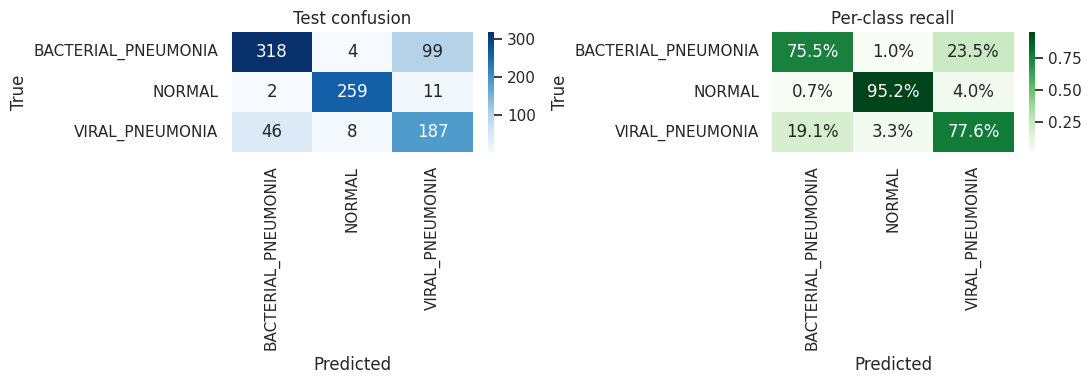

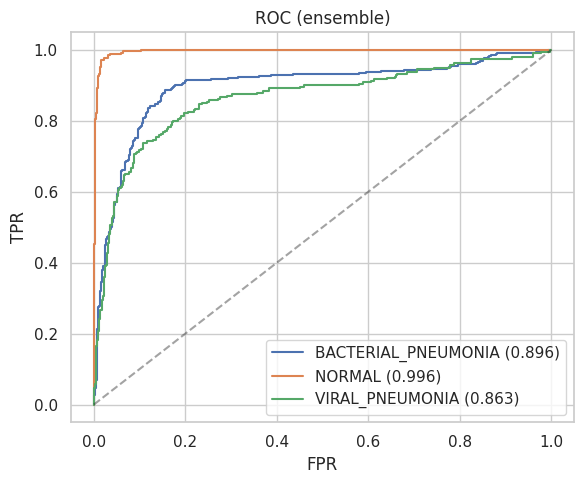

In [15]:
def plot_cm(y, pred, title):
    cm = confusion_matrix(y, pred)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes, ax=ax[0])
    sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt=".1%", cmap="Greens", xticklabels=classes, yticklabels=classes, ax=ax[1])
    ax[0].set_title(title); ax[1].set_title("Per-class recall")
    for a in ax: a.set_xlabel("Predicted"); a.set_ylabel("True")
    plt.tight_layout(); plt.savefig(Path(cfg.out_dir) / f"{title.replace(' ', '_')}.png", dpi=150); plt.show()

plot_cm(y_test, test_probs.argmax(1), "Test confusion")

plt.figure(figsize=(6, 5))
Y = label_binarize(y_test, classes=np.arange(NUM_CLASSES))
for i, c in enumerate(classes):
    f_, t_, _ = roc_curve(Y[:, i], test_probs[:, i])
    plt.plot(f_, t_, label=f"{c} ({roc_auc_score(Y[:, i], test_probs[:, i]):.3f})")
plt.plot([0, 1], [0, 1], "k--", alpha=.4); plt.legend(); plt.xlabel("FPR"); plt.ylabel("TPR"); plt.title("ROC (ensemble)")
plt.tight_layout(); plt.savefig(Path(cfg.out_dir) / "roc.png", dpi=150); plt.show()

<div dir="rtl" style="text-align:right">

## 1️⃣3️⃣ Grad-CAM وتحليل الأخطاء

</div>

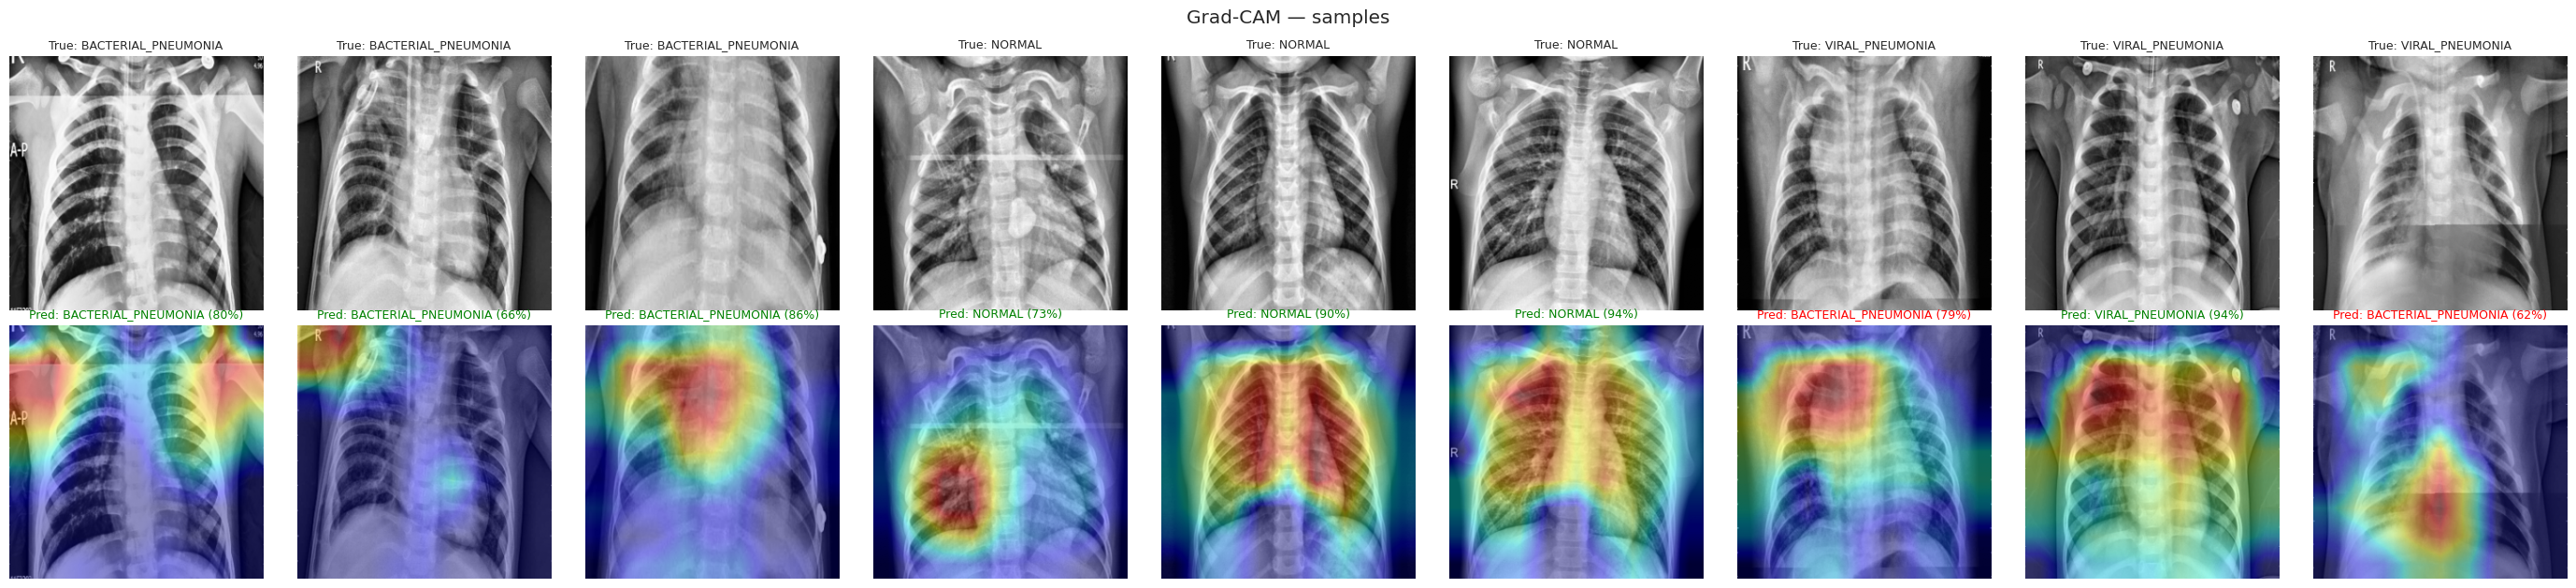

Errors: 170 / 934


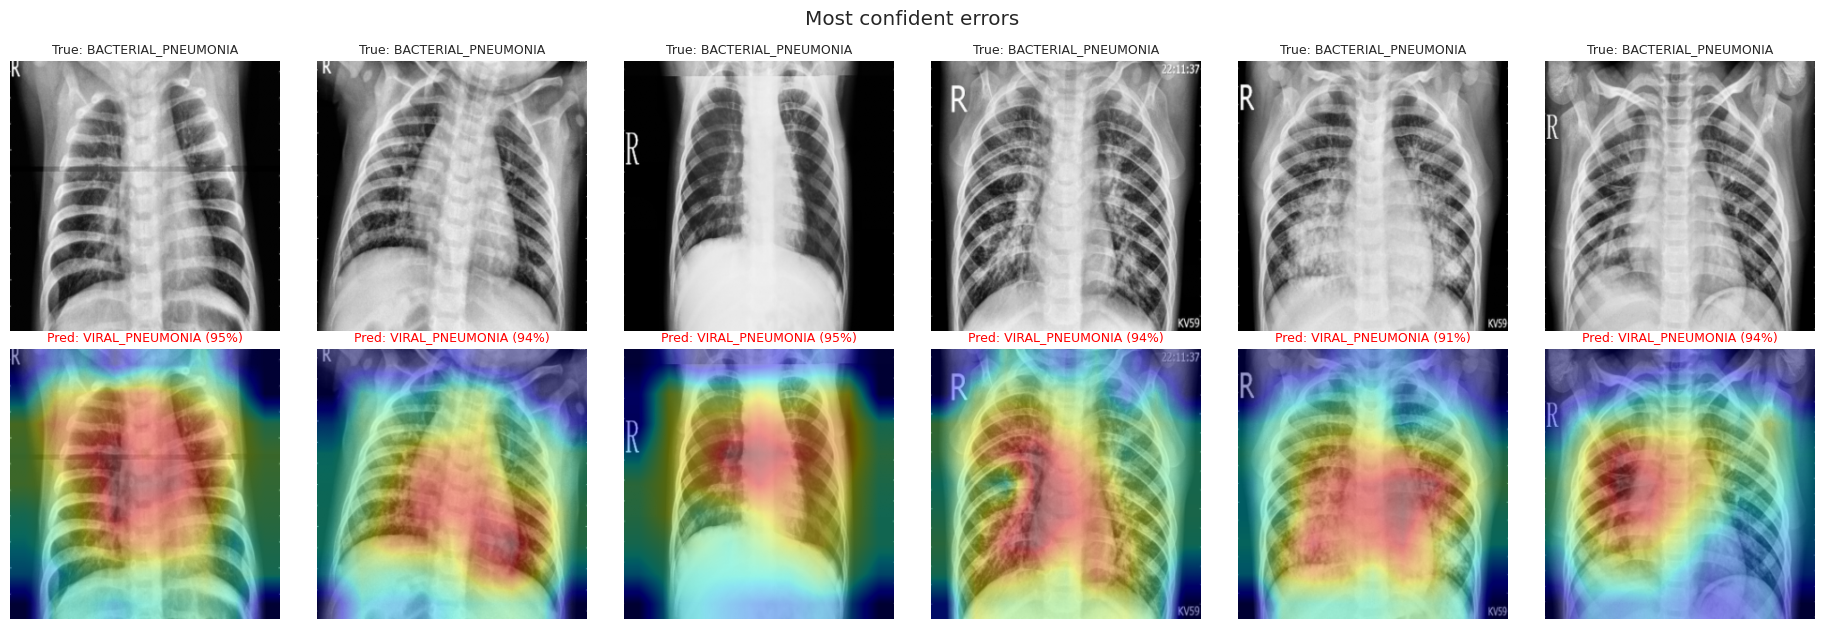

In [16]:
class GradCAM:
    def __init__(self, model, layer):
        self.model, self.acts, self.grads = model, None, None
        layer.register_forward_hook(self._fwd)
    def _fwd(self, m, i, o):
        self.acts = o.detach()
        if o.requires_grad: o.register_hook(lambda g: setattr(self, "grads", g.detach()))
    def __call__(self, x, cls=None):
        self.model.eval()
        with torch.enable_grad():
            lg = self.model(x)
            probs = F.softmax(lg, 1)[0].detach().cpu().numpy()
            cls = int(lg.argmax(1)) if cls is None else cls
            self.model.zero_grad(set_to_none=True); lg[0, cls].backward()
        w = self.grads.mean((2, 3), keepdim=True)
        cam = F.relu((w * self.acts).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam.cpu().numpy(), cls, probs

best_k = int(np.argmax([r["best"] for r in fold_results]))
cam_model = ens_models[best_k]
gradcam = GradCAM(cam_model, gradcam_layer(cam_model))

def show_cams(rows, title, fname):
    fig, ax = plt.subplots(2, len(rows), figsize=(3.1 * len(rows), 6.4), squeeze=False)
    for k, (_, r) in enumerate(rows.iterrows()):
        x = eval_tfm(torch.from_numpy(CACHE[r.path]).unsqueeze(0)).unsqueeze(0).to(device)
        cam, pred, probs = gradcam(x); img = x[0, 0].cpu().numpy()
        ax[0, k].imshow(img, cmap="gray"); ax[0, k].set_title(f"True: {classes[r.y]}", fontsize=9)
        ax[1, k].imshow(img, cmap="gray"); ax[1, k].imshow(cam, cmap="jet", alpha=0.4)
        ax[1, k].set_title(f"Pred: {classes[pred]} ({probs[pred]:.0%})", fontsize=9, color="green" if pred == r.y else "red")
        ax[0, k].axis("off"); ax[1, k].axis("off")
    fig.suptitle(title); plt.tight_layout(); plt.savefig(Path(cfg.out_dir) / fname, dpi=150); plt.show()

ok = pd.concat([test_df[test_df.y == i].sample(min(3, (test_df.y == i).sum()), random_state=0) for i in range(NUM_CLASSES)])
show_cams(ok, "Grad-CAM — samples", "gradcam_samples.png")
err = test_df.assign(pred=test_probs.argmax(1), conf=test_probs.max(1))
err = err[err.pred != err.y].sort_values("conf", ascending=False).head(6)
print(f"Errors: {(test_probs.argmax(1) != y_test).sum()} / {len(y_test)}")
if len(err): show_cams(err, "Most confident errors", "gradcam_errors.png")

<div dir="rtl" style="text-align:right">

## 1️⃣4️⃣ الاستدلال والتصدير

</div>

In [17]:
def prepare_image(path):
    x = torch.from_numpy(load_gray(path)).unsqueeze(0)
    return eval_tfm(x).unsqueeze(0).to(device)

@torch.no_grad()
def predict_image(path):
    x = prepare_image(path)
    with torch.autocast(device_type=device.type, enabled=cfg.use_amp):
        lg = np.mean([(tta_forward(m, x) if USE_TTA else m(x).float()).float().cpu().numpy() for m in ens_models], axis=0)
    p = softmax_np(lg + LOGIT_BIAS, T_OPT)[0]
    return {"prediction": classes[int(p.argmax())], "confidence": float(p.max()),
            "probabilities": {c: float(v) for c, v in zip(classes, p)}}

s = test_df.sample(1, random_state=3).iloc[0]
print("True:", s.label); print(json.dumps(predict_image(s.path), indent=2, ensure_ascii=False))

True: VIRAL_PNEUMONIA
{
  "prediction": "VIRAL_PNEUMONIA",
  "confidence": 0.9663450686014015,
  "probabilities": {
    "BACTERIAL_PNEUMONIA": 0.020900134120761655,
    "NORMAL": 0.012754797277836885,
    "VIRAL_PNEUMONIA": 0.9663450686014015
  }
}


In [18]:
try:
    export_model = copy.deepcopy(ens_models[best_k]).cpu().eval()
    dummy = torch.rand(1, 1, cfg.img_size, cfg.img_size)
    torch.jit.trace(export_model, dummy).save(str(Path(cfg.out_dir) / f"{cfg.backbone}_traced.pt"))
    try:
        import onnxscript
    except ImportError:
        _pip("onnx", "onnxscript")
    torch.onnx.export(export_model, dummy, str(Path(cfg.out_dir) / f"{cfg.backbone}.onnx"),
                      input_names=["image"], output_names=["logits"],
                      dynamic_axes={"image": {0: "batch"}, "logits": {0: "batch"}}, opset_version=18)
except Exception as e:
    print("تعذّر التصدير (غير حرج):", e)

deploy = {"classes": classes, "backbone": cfg.backbone, "img_size": cfg.img_size, "cache_size": cfg.cache_size,
          "preprocess": "grayscale -> resize(cache_size) -> CLAHE(2.0, 8x8) -> resize(img_size) -> /255",
          "temperature": T_OPT, "logit_bias": LOGIT_BIAS.tolist(), "use_tta": bool(USE_TTA),
          "oof_metrics": {k: float(v) for k, v in (m_tta if USE_TTA else m_plain).items()},
          "test_metrics": {k: float(v) for k, v in metrics.items()}, "config": asdict(cfg)}
with open(Path(cfg.out_dir) / "deploy_config.json", "w", encoding="utf-8") as f:
    json.dump(deploy, f, indent=2, ensure_ascii=False)
print(sorted(p.name for p in Path(cfg.out_dir).iterdir()))

# (اختياري على Colab) نسخ المخرجات إلى Drive:
# from google.colab import drive; drive.mount('/content/drive')
# import shutil; shutil.copytree(cfg.out_dir, "/content/drive/MyDrive/" + cfg.out_dir, dirs_exist_ok=True)

[torch.onnx] Obtain model graph for `XrayNet([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `XrayNet([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
['Test_confusion.png', 'cv_curves.png', 'deploy_config.json', 'efficientnetv2_s.onnx', 'efficientnetv2_s.onnx.data', 'efficientnetv2_s_fold1.pt', 'efficientnetv2_s_fold2.pt', 'efficientnetv2_s_fold3.pt', 'efficientnetv2_s_fold4.pt', 'efficientnetv2_s_fold5.pt', 'efficientnetv2_s_traced.pt', 'gradcam_errors.png', 'gradcam_samples.png', 'roc.png']


<div dir="rtl" style="text-align:right">

## 1️⃣5️⃣ إن لم ترضَ عن النتيجة: ماذا تفعل؟

| الملاحظة | التشخيص | الإجراء |
|---|---|---|
| فحص إعادة التحميل يفشل | خلل حفظ/تحميل أو AMP | شغّل بـ `use_amp=False` وراجع نسخة timm/torch |
| OOF جيد و Test أسوأ بكثير | تسرب في CV أو اختلاف توزيع | قلّل `NEAR_DUP_MAX_HAMMING`، راجع `patient_id`، اختبر على مجموعة خارجية |
| Train loss منخفض و Val NLL يرتفع | Overfitting | ارفع `mix_prob` و`weight_decay` و`dropout`، قلّل `epochs` |
| الاثنان مرتفعان | Underfitting | ارفع `lr_backbone` إلى 3e-4، زِد `epochs`، أو ارفع `img_size` إلى 384 |
| Viral ↔ Bacterial يختلطان | حدّ طبيعي للفصل البصري | جرّب `convnext_tiny` أو `xrv_densenet121` وقارن، وأضف بيانات (CheXpert/NIH) |
| Grad-CAM على حواف/نصوص | Shortcut learning | قص الحواف أو قناع للرئتين |

**ملاحظة عن الحد الأعلى الواقعي:** تقييم Viral مقابل Bacterial من صورة واحدة محدود بطبيعته؛ في هذه المجموعة تُعدّ نتائج صادقة بين ~85% و~92% (حسب التقسيم) نتيجة جيدة. نتيجة 100% يجب التعامل معها كإنذار تسرب لا كإنجاز.

</div>